In [1]:
# ============================================================
#IMPORT LIBRARIES AND LOAD DATA
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy import stats
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

# Support running from either the project root or the notebook directory.
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data").exists() and (PROJECT_DIR.parent / "data").exists():
    PROJECT_DIR = PROJECT_DIR.parent
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

files = sorted(DATA_DIR.glob("gt_*.csv"))
if not files:
    raise FileNotFoundError(f"Gas turbine CSV files not found in {DATA_DIR.resolve()}")

frames = []
for file in files:
    frame = pd.read_csv(file)
    frame["Year"] = int(file.stem.split("_")[-1])
    frames.append(frame)

data = pd.concat(frames, ignore_index=True)

feature_cols = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "CDP"]
target_cols = ["TEY", "CO", "NOX"]

print("Dataset shape:", data.shape)
print("Years:", sorted(data["Year"].unique()))
print("Features:", feature_cols)
print("Targets:", target_cols)
display(data.head())


Dataset shape: (36733, 12)
Years: [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015)]
Features: ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'CDP']
Targets: ['TEY', 'CO', 'NOX']


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,Year
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952,2011
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377,2011
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776,2011
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505,2011
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028,2011


In [2]:
# ============================================================
# TEMPORAL TRAIN / COMPARISON SPLIT
# ============================================================

train_data = data[data["Year"] <= 2014].copy()
test_data = data[data["Year"] == 2015].copy()

X_train = train_data[feature_cols]
X_test = test_data[feature_cols]
Y_train = train_data[target_cols]
Y_test = test_data[target_cols]

print("Training observations:", len(X_train))
print("Comparison observations:", len(X_test))
print("Training years:", sorted(train_data["Year"].unique()))
print("Comparison years:", sorted(test_data["Year"].unique()))

assert len(train_data) > 0 and len(test_data) > 0
assert train_data["Year"].max() < test_data["Year"].min()
assert not X_train.isna().any().any() and not X_test.isna().any().any()


Training observations: 29349
Comparison observations: 7384
Training years: [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014)]
Comparison years: [np.int64(2015)]


In [3]:
# ============================================================
# TRAIN GRADIENT BOOSTING MODELS
# ============================================================

gb_params = {
    "n_estimators": 100,
    "learning_rate": 0.05,
    "max_depth": 2,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "subsample": 0.8,
    "loss": "squared_error",
    "random_state": RANDOM_STATE
}

gb_models = {}
for target in target_cols:
    print("\n" + "=" * 55)
    print("Starting Gradient Boosting fit for:", target)
    model = GradientBoostingRegressor(**gb_params)
    model.fit(X_train, Y_train[target])
    gb_models[target] = model
    print("Completed Gradient Boosting fit for:", target)

print("\nAll target models trained.")



Starting Gradient Boosting fit for: TEY
Completed Gradient Boosting fit for: TEY

Starting Gradient Boosting fit for: CO
Completed Gradient Boosting fit for: CO

Starting Gradient Boosting fit for: NOX
Completed Gradient Boosting fit for: NOX

All target models trained.


In [4]:
# ============================================================
# MODEL CONFIGURATION
# ============================================================

model_configuration = pd.DataFrame([
    {"Target": target, "Model": "Gradient Boosting",
     "Parameters": str(gb_models[target].get_params())}
    for target in target_cols
])
display(model_configuration)


,Target,Model,Parameters
0,TEY,Gradient Boosting,"{'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': ..."
1,CO,Gradient Boosting,"{'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': ..."
2,NOX,Gradient Boosting,"{'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': ..."


In [5]:
# ============================================================
# COMPARISON BENCHMARK EVALUATION
# ============================================================

def evaluate_model(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

gb_predictions = {}
gb_results = []
for target in target_cols:
    pred = gb_models[target].predict(X_test)
    gb_predictions[target] = pred
    gb_results.append({"Model": "Gradient Boosting", "Target": target,
                       **evaluate_model(Y_test[target], pred)})
gb_results_df = pd.DataFrame(gb_results)
display(gb_results_df.round(4))


,Model,Target,MAE,RMSE,R2
0,Gradient Boosting,TEY,1.3066,1.7824,0.9879
1,Gradient Boosting,CO,0.9243,1.5089,0.5441
2,Gradient Boosting,NOX,8.9220,10.4065,0.1260


========== MODEL COMPARISON: 2015 FIXED BENCHMARK ==========


,Model,Target,MAE,RMSE,R2
13,Gradient Boosting,CO,0.9243,1.5089,0.5441
10,Random Forest,CO,1.0069,1.5948,0.4908
7,Ridge Regression,CO,1.3388,1.8881,0.2862
4,Linear Regression,CO,1.3670,1.9241,0.2587
1,Mean Predictor,CO,1.3919,2.4276,-0.1800
5,Linear Regression,NOX,8.1810,10.2146,0.1580
8,Ridge Regression,NOX,8.2403,10.2731,0.1483
14,Gradient Boosting,NOX,8.9220,10.4065,0.1260
11,Random Forest,NOX,9.1212,11.0834,0.0087
2,Mean Predictor,NOX,11.1144,13.0245,-0.3690


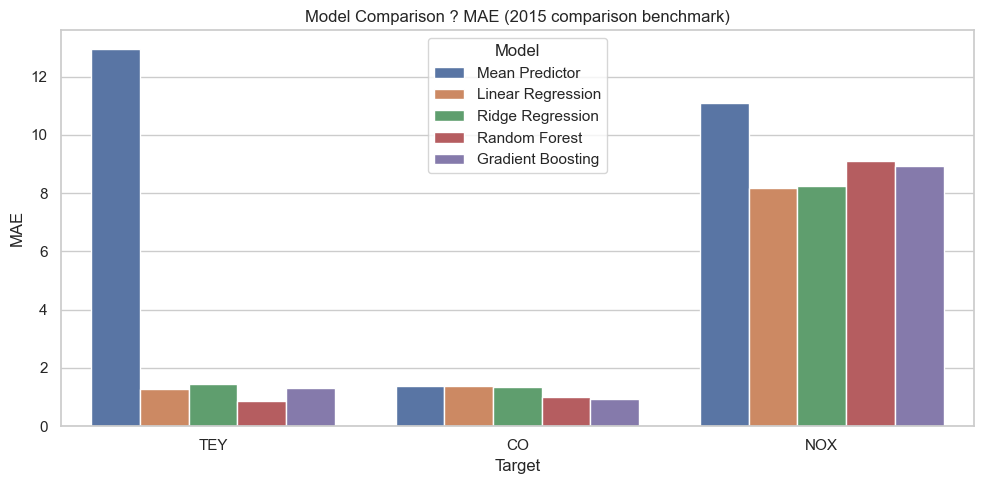

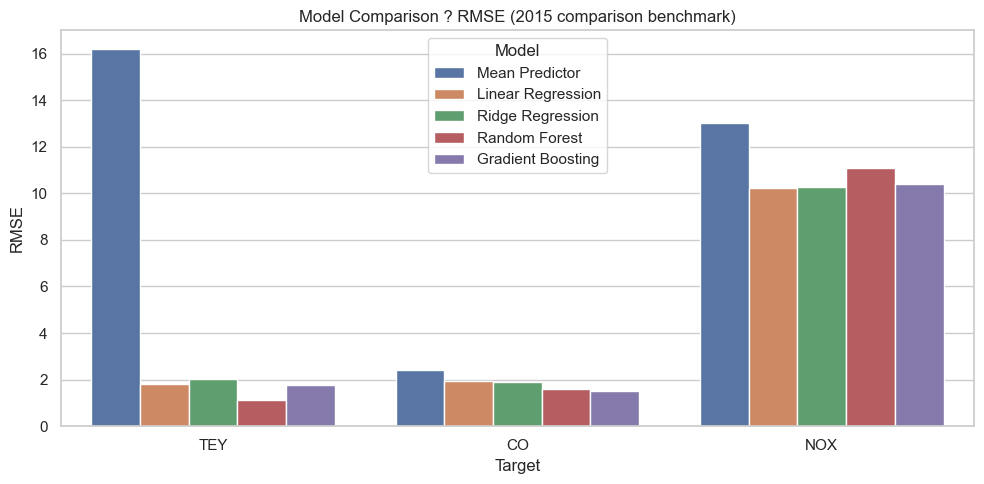

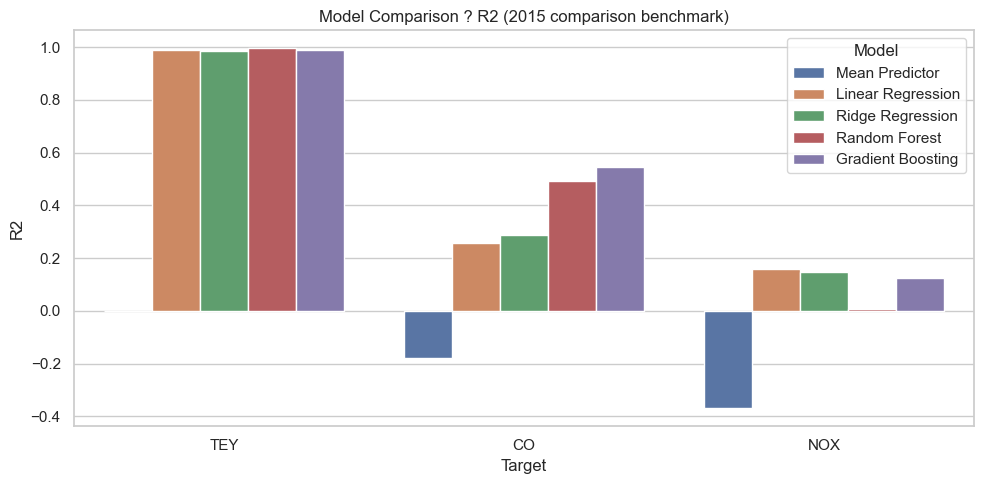

In [6]:
# ============================================================
# MODEL COMPARISON TABLE AND PLOTS
# ============================================================

baseline_path = OUTPUT_DIR / "baseline_temporal_results.csv"
rf_path = OUTPUT_DIR / "random_forest_temporal_results.csv"
for path in (baseline_path, rf_path):
    if not path.exists():
        raise FileNotFoundError(f"Required comparison results not found: {path}")

baseline_results = pd.read_csv(baseline_path)
rf_results = pd.read_csv(rf_path)
required_columns = {"Model", "Target", "MAE", "RMSE", "R2"}
for name, frame in [("baseline", baseline_results), ("random forest", rf_results)]:
    missing = required_columns.difference(frame.columns)
    if missing:
        raise ValueError(f"{name} results are missing columns: {sorted(missing)}")

all_models_comparison = pd.concat(
    [baseline_results, rf_results, gb_results_df], ignore_index=True
)
all_models_comparison = all_models_comparison.drop_duplicates(
    subset=["Model", "Target"], keep="last"
)
print("========== MODEL COMPARISON: 2015 FIXED BENCHMARK ==========")
display(all_models_comparison.sort_values(["Target", "RMSE"]).round(4))

for metric in ["MAE", "RMSE", "R2"]:
    plt.figure(figsize=(10, 5))
    sns.barplot(data=all_models_comparison, x="Target", y=metric, hue="Model")
    plt.title(f"Model Comparison ? {metric} (2015 comparison benchmark)")
    plt.ylabel(metric)
    plt.xlabel("Target")
    plt.tight_layout()
    plt.show()


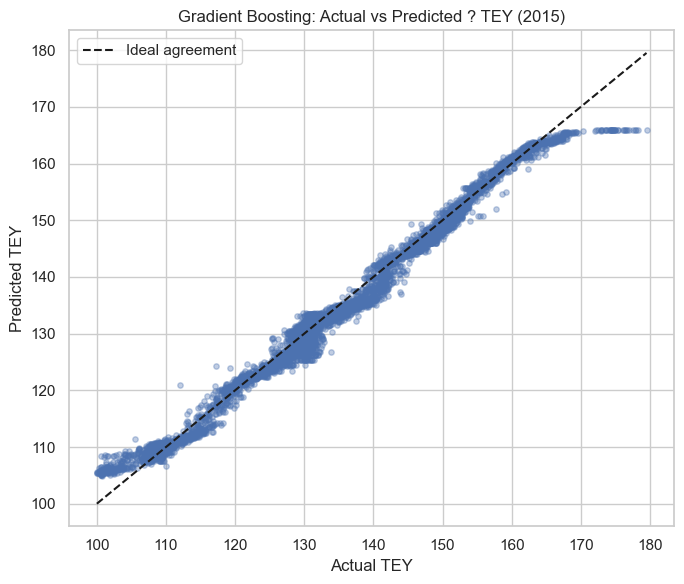

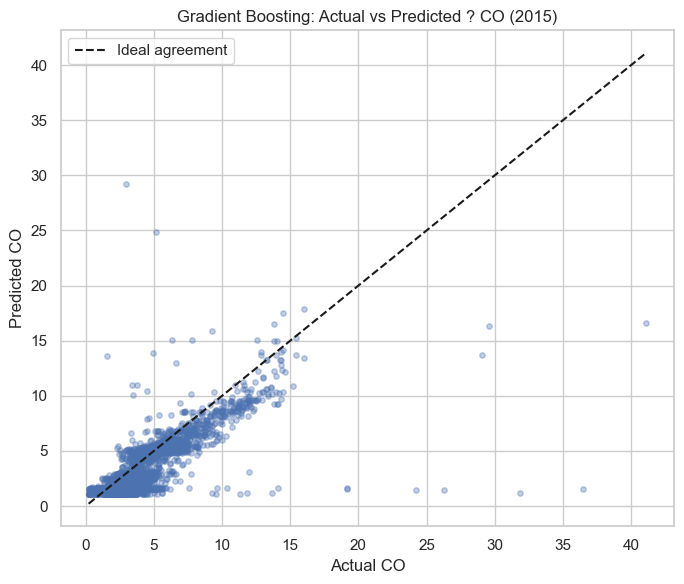

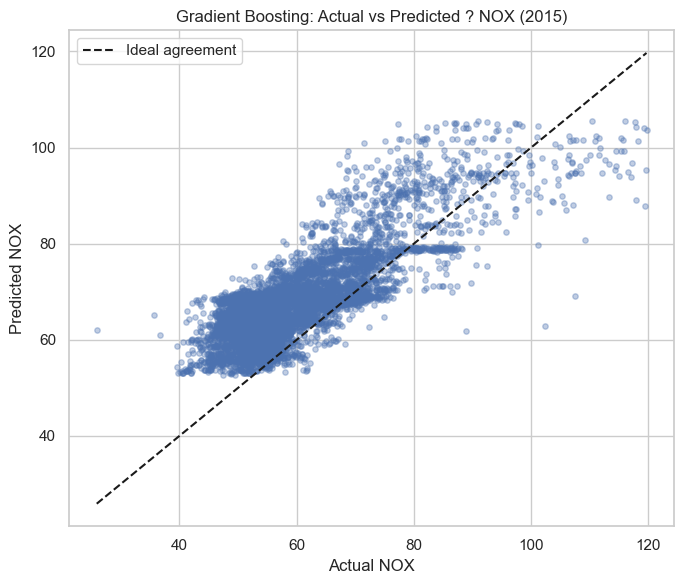

In [7]:
# ============================================================
# ACTUAL VS PREDICTED
# ============================================================

for target in target_cols:
    actual = Y_test[target].to_numpy()
    predicted = gb_predictions[target]
    plt.figure(figsize=(7, 6))
    plt.scatter(actual, predicted, alpha=0.35, s=15)
    lower = min(actual.min(), predicted.min())
    upper = max(actual.max(), predicted.max())
    plt.plot([lower, upper], [lower, upper], "k--", label="Ideal agreement")
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Gradient Boosting: Actual vs Predicted ? {target} (2015)")
    plt.legend()
    plt.tight_layout()
    plt.show()


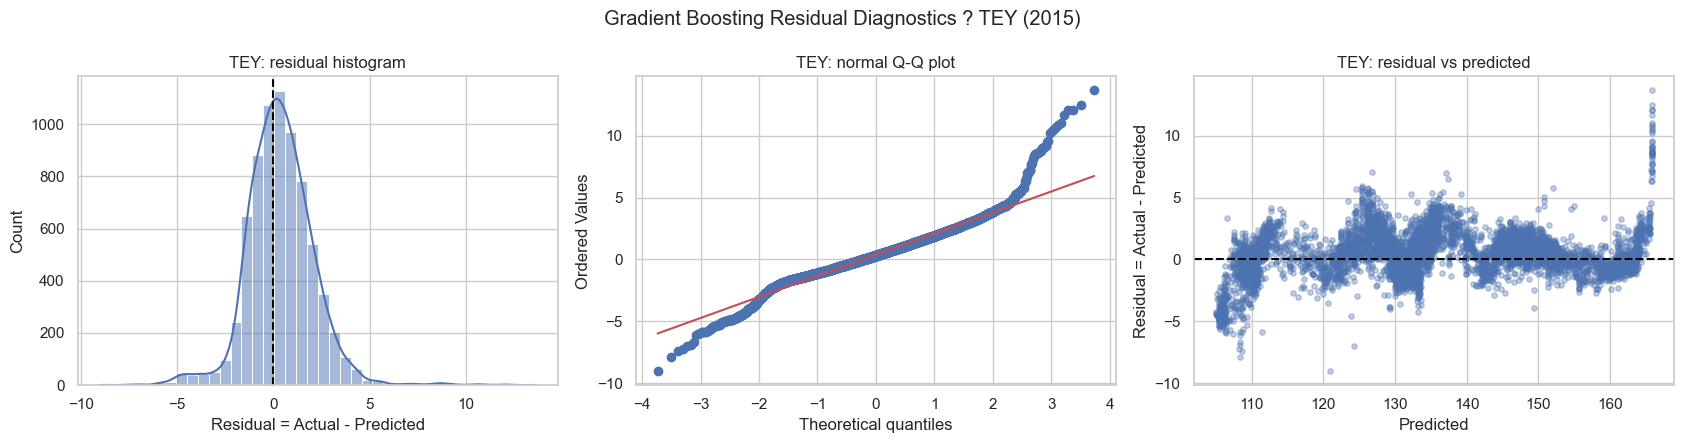

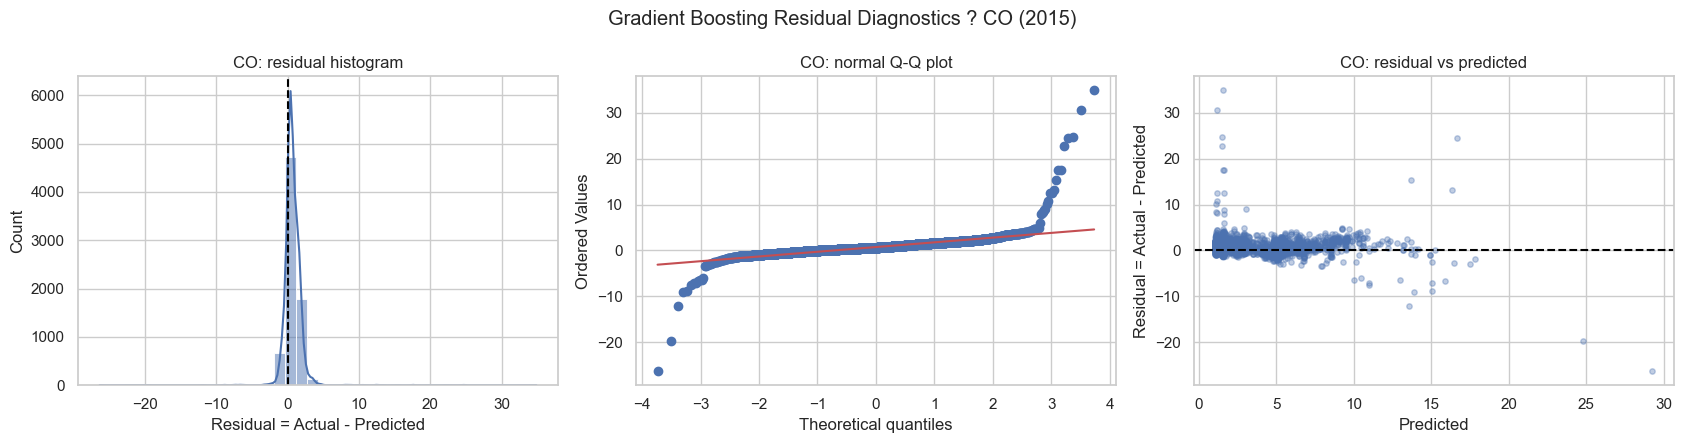

CO residual quantiles:


,Residual
0.00,-26.333178
0.01,-1.305412
0.50,0.597010
0.99,3.461868
1.00,34.869365


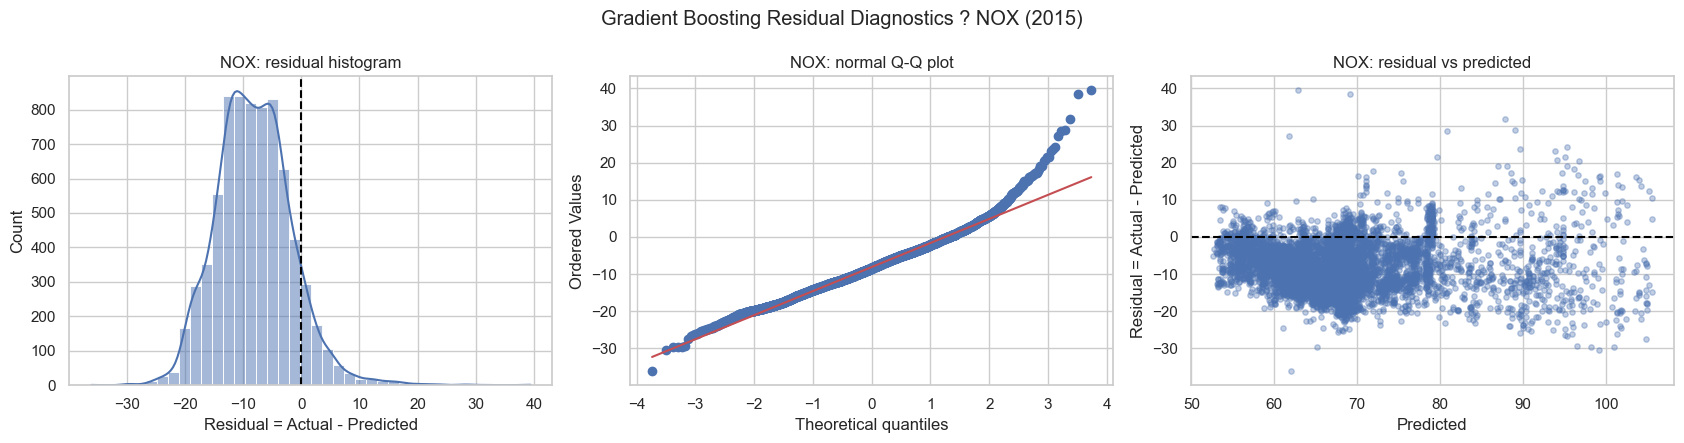

NOX residual quantiles:


,Residual
0.00,-36.107872
0.01,-21.467982
0.50,-8.374989
0.99,10.089048
1.00,39.436752


In [8]:
# ============================================================
# RESIDUAL HISTOGRAMS, Q-Q PLOTS, AND RESIDUAL VS PREDICTED
# ============================================================

gb_residuals = {}
for target in target_cols:
    actual = Y_test[target].to_numpy()
    predicted = gb_predictions[target]
    residuals = actual - predicted
    gb_residuals[target] = residuals

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    sns.histplot(residuals, bins=40, kde=True, ax=axes[0])
    axes[0].axvline(0, color="black", linestyle="--")
    axes[0].set_title(f"{target}: residual histogram")
    axes[0].set_xlabel("Residual = Actual - Predicted")

    stats.probplot(residuals, dist="norm", plot=axes[1])
    axes[1].set_title(f"{target}: normal Q-Q plot")

    axes[2].scatter(predicted, residuals, alpha=0.35, s=15)
    axes[2].axhline(0, color="black", linestyle="--")
    axes[2].set_xlabel("Predicted")
    axes[2].set_ylabel("Residual = Actual - Predicted")
    axes[2].set_title(f"{target}: residual vs predicted")
    fig.suptitle(f"Gradient Boosting Residual Diagnostics ? {target} (2015)")
    plt.tight_layout()
    plt.show()

    if target in ["CO", "NOX"]:
        print(f"{target} residual quantiles:")
        display(pd.Series(residuals).quantile([0, .01, .5, .99, 1]).to_frame("Residual"))


Feature importance for TEY


,Feature,Importance
7,CDP,0.926271
5,TIT,0.054577
0,AT,0.012508
4,GTEP,0.006256
6,TAT,0.000387
3,AFDP,0.000000
1,AP,0.000000
2,AH,0.000000


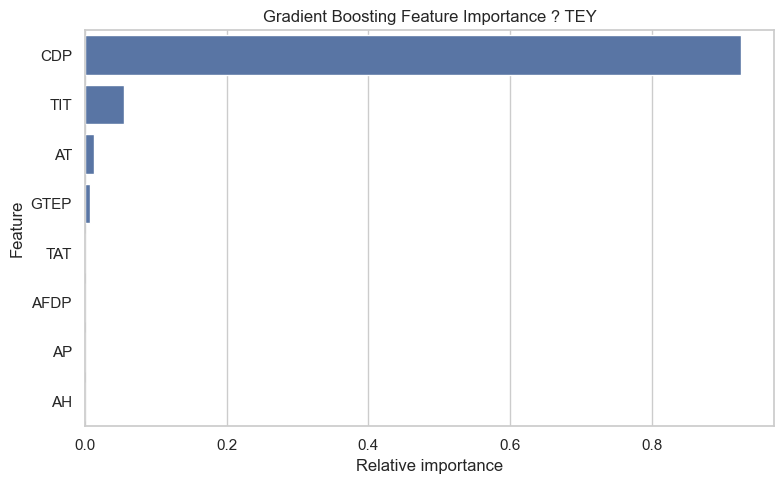

Feature importance for CO


,Feature,Importance
5,TIT,0.669403
6,TAT,0.215325
7,CDP,0.050206
4,GTEP,0.047269
0,AT,0.007072
1,AP,0.004870
3,AFDP,0.004810
2,AH,0.001045


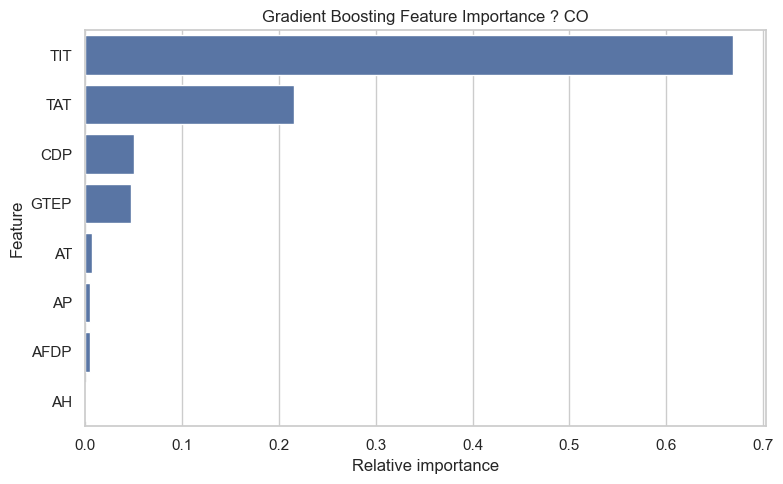

Feature importance for NOX


,Feature,Importance
0,AT,0.523733
5,TIT,0.202809
4,GTEP,0.177751
6,TAT,0.049049
2,AH,0.034218
3,AFDP,0.006176
7,CDP,0.005945
1,AP,0.000319


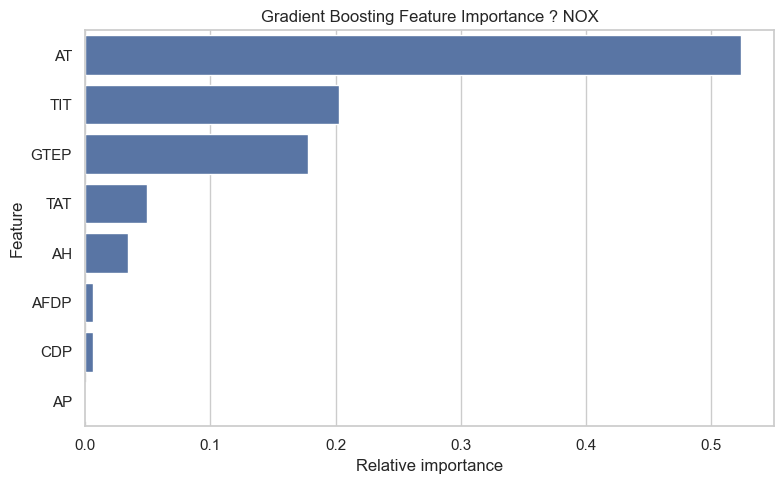

In [9]:
# ============================================================
# FEATURE IMPORTANCE
# ============================================================

gb_feature_importance = {}
for target in target_cols:
    importance = pd.DataFrame({
        "Feature": feature_cols,
        "Importance": gb_models[target].feature_importances_
    }).sort_values("Importance", ascending=False)
    gb_feature_importance[target] = importance
    print(f"Feature importance for {target}")
    display(importance)
    plt.figure(figsize=(8, 5))
    sns.barplot(data=importance, x="Importance", y="Feature")
    plt.title(f"Gradient Boosting Feature Importance ? {target}")
    plt.xlabel("Relative importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


In [10]:
# ============================================================
# SAVE RESULTS
# ============================================================

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
gb_results_df.to_csv(OUTPUT_DIR / "gradient_boosting_temporal_results.csv", index=False)
model_configuration.to_csv(OUTPUT_DIR / "gradient_boosting_model_configuration.csv", index=False)
all_models_comparison.to_csv(OUTPUT_DIR / "all_models_comparison.csv", index=False)

gb_prediction_output = test_data[["Year"]].copy()
for target in target_cols:
    gb_prediction_output[f"{target}_actual"] = Y_test[target].to_numpy()
    gb_prediction_output[f"{target}_gradient_boosting"] = gb_predictions[target]
gb_prediction_output.to_csv(
    OUTPUT_DIR / "gradient_boosting_2015_predictions.csv", index=False
)

print("Saved outputs to:", OUTPUT_DIR.resolve())
for filename in [
    "gradient_boosting_temporal_results.csv",
    "gradient_boosting_model_configuration.csv",
    "gradient_boosting_2015_predictions.csv",
    "all_models_comparison.csv"
]:
    print("-", filename)


Saved outputs to: C:\Users\devra\Music\gas-turbine-ml\outputs
- gradient_boosting_temporal_results.csv
- gradient_boosting_model_configuration.csv
- gradient_boosting_2015_predictions.csv
- all_models_comparison.csv
